# Per-stock square-root market-impact fit

We calibrate the **per-stock coefficient $\gamma_i$** for the square-root (Almgren / BARRA)
impact law used by the optimizer:

$$
\underbrace{I_i}_{\text{return impact}} \;=\; \gamma_i \; \sigma_i \;
\sqrt{\dfrac{Q^{\$}_i}{\mathrm{ADV}^{\$}_i}},
\qquad
\underbrace{\text{cost}_i}_{\text{\$}} \;=\; \gamma_i \; \sigma_i \;
\dfrac{|Q^{\$}_i|^{3/2}}{\sqrt{\mathrm{ADV}^{\$}_i}}.
$$

Deployment geometry (matched here so the fitted $\gamma$ plugs in directly):

- $Q^{\$}_i$ = **net signed dollar flow** over the 15:50-16:00 closing window
- $\mathrm{ADV}^{\$}_i$ = **causal daily** dollar volume (EWMA span-10 over prior full-session
  daily $-volume, shifted 1 day; same construction as the optimizer)
- $\sigma_i$ = **daily** return volatility (std of close-to-close returns; full-sample
  normalizer, not time-varying)

## Estimator (aggregate impact, $\sigma / $ADV normalized)

Per (name, day), from the tbbo tape alone:

- $p_0$ = arrival mid (first mid at $\approx$ 15:50:00)
- $p_1$ = end-of-window mid (last mid $<$ 16:00:00)
- $Q$ = $\sum_t s_t \cdot \text{size}_t \cdot \text{price}_t$ with Lee-Ready trade signs
  (trust `side` B/A; fall back to quote rule vs. mid; fall back to tick rule)
- $r$ = $p_1 / p_0 - 1$
- $r_\text{idio}$ = $r$ - cross-sectional mean of $r$ across all names that day (strips
  the market move so what is left is the name's own drift)

Then per-stock, through the origin:

$$
\underbrace{y_{i,d}}_{r_{\text{idio}} \,/\, \sigma_i}
\;=\; \gamma_i \cdot
\underbrace{x_{i,d}}_{\text{sign}(Q) \,\sqrt{|Q|/\mathrm{ADV}}}
\;+\; \varepsilon_{i,d}.
$$

## Robustness / thin-sample tricks

- Per-name $N \approx 140$ day-obs, and flow is fat-tailed. So:
  1. **Winsorize** $x, y$ at the 1st / 99th percentiles.
  2. Fit each slope with a **Huber regressor through the origin** (falls back to a robust
     Theil-Sen if Huber fails to converge).
  3. Compute the **pooled** $\gamma$ across all name-days (the universal constant) and
     **shrink** each per-name $\hat\gamma_i$ toward the pooled value with a partial-pooling
     rule $\hat\gamma_i^{\text{shrunk}} = w_i\, \hat\gamma_i + (1-w_i)\, \bar\gamma$, weight
     $w_i = \frac{n_i}{n_i + n_0}$ with $n_0$ set from the between-name variance.
- Non-finite, wrong-signed ($\hat\gamma_i < 0$), or missing-data names are replaced with the
  pooled $\gamma$. **$\gamma$ must be $\ge 0$** (impact is positive).

## Caveats (read once)

1. **Identification is intrinsically hard**. Anonymous tbbo cannot separate mechanical
   impact from information: informed flow both *moves* and *predicts* price. So $\gamma$
   here is an *effective, conservative-leaning* estimate. It should ultimately be **swept**
   inside the optimizer, not trusted to 3 sig-figs.
2. **Deployment horizon**: $\gamma$ is fit at the 10-minute closing window with **daily**
   $\sigma$ / **daily** ADV normalization, matching how the optimizer applies it.
3. **Per-name fits are noisy** ($N\!\approx\!140$), which is why we shrink toward the
   pool. If any per-name fit disagrees violently with the pool, trust the pool.


In [1]:
# --- Setup: adapter, env, universe, window --------------------------------------
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt

load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)
print(f"CACHE_DIR: {CACHE_DIR}")

# Broad pool for the tbbo scan (the parquet is keyed on this list) and the active
# top-100 universe consumed positionally by the optimizer.  Alignment to top_100
# order (file order) is what makes the saved vector loadable in the optimizer.
with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
with open("../top_100_universe.txt", "r") as f:
    ACTIVE_SET = [line.strip() for line in f]

START = "2025-06-11"
END = "2026-06-11"
DATASET = "XNAS.ITCH"

print(f"universe={len(UNIVERSE)} active_set={len(ACTIVE_SET)}")


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
universe=2000 active_set=100


In [2]:
# --- Lazy tbbo scan (whole session, ACTIVE_SET only) ----------------------------
# Cache is already warm, so scan_data is fast.  We restrict to the top-100 active
# set now (a) so the daily x-sectional mean of r is computed over the same names
# we will fit, and (b) so per-day ADV excludes irrelevant tickers.  Times are
# converted to America/New_York; the raw UTC filter (13:30-21:00) is a safety
# prefilter that survives DST both ways.
tbbo = (
    adapter.scan_data(
        tickers=UNIVERSE, start_date=START, end_date=END,
        dataset=DATASET, schema="tbbo",
    )
    .select(["ts_event", "symbol", "price", "side", "size", "ask_px_00", "bid_px_00"])
    .filter(
        pl.col("ts_event").dt.time().is_between(pl.time(13, 30), pl.time(21, 0)),
        pl.col("symbol").is_in(ACTIVE_SET),
    )
    .with_columns(pl.col("ts_event").dt.convert_time_zone("America/New_York"))
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(9, 30), pl.time(16, 0)))
    .with_columns(
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"),
        pl.col("symbol").cast(pl.Categorical),
        pl.col("ts_event").dt.date().alias("date"),
    )
)
print("tbbo LazyFrame ready")


[GenericAdapter] scan_parquet: 6436dd54a7ced32262a3242e08d42d20.parquet
tbbo LazyFrame ready


In [3]:
# --- 15:50-16:00 window aggregates: Q (signed $ flow), p0 (arrival), p1 (end) ---
# Lee-Ready signs: trust `side` first (B -> +1, A -> -1); on side=='N' or null,
# fall back to the quote rule (trade vs mid); if the trade prints exactly at the
# mid, fall back to the tick rule (previous trade price move within the same
# symbol).  Anything still ambiguous is dropped from Q by treating sign as 0
# below.  Note: the *sum* of signed dollar flow (Q) is robust to a few
# unclassified trades; a small residue is not a problem.
window = (
    tbbo
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15, 50), pl.time(16, 0)))
    .sort("symbol", "ts_event")
    .with_columns(
        pl.when(pl.col("price") > pl.col("mid")).then(1)
          .when(pl.col("price") < pl.col("mid")).then(-1)
          .otherwise(None).alias("quote_sign"),
        pl.when(pl.col("price").diff().over("symbol") > 0).then(1)
          .when(pl.col("price").diff().over("symbol") < 0).then(-1)
          .otherwise(None).alias("tick_sign"),
    )
    .with_columns(pl.col("tick_sign").forward_fill().over("symbol"))
    .with_columns(
        pl.when(pl.col("side") == "B").then(1)
          .when(pl.col("side") == "A").then(-1)
          .otherwise(pl.coalesce("quote_sign", "tick_sign"))
          .alias("trade_sign")
    )
)

# Per (symbol, date): first mid in the window is arrival p0, last mid is p1, Q
# is the sum of signed dollar flow.  Unsigned trades contribute 0 to Q.
per_day_window = (
    window
    .group_by(["symbol", "date"])
    .agg(
        pl.col("mid").first().alias("p0"),
        pl.col("mid").last().alias("p1"),
        (
            pl.col("trade_sign").fill_null(0).cast(pl.Float64)
            * pl.col("size").cast(pl.Float64) * pl.col("price")
        ).sum().alias("Q"),
        pl.len().alias("n_trades"),
    )
    .collect(engine="streaming")
)
per_day_window


symbol,date,p0,p1,Q,n_trades
cat,date,f64,f64,f64,u64
"""ABNB""",2025-09-18,125.465,125.435,1.9985e6,4596
"""AMGN""",2025-08-21,295.3,295.835,-58441.975,1557
"""IBKR""",2025-10-08,72.085,72.055,1.1968e6,2853
"""LRCX""",2025-07-31,94.045,94.845,1.2598e7,10013
"""CSX""",2026-02-09,40.725,40.725,-3.2573e6,2714
…,…,…,…,…,…
"""ULTA""",2026-05-27,507.115,507.265,-810177.54,1440
"""WDC""",2025-07-10,64.96,65.06,-1.4698e6,2616
"""WDC""",2025-08-04,76.945,77.285,2.9263e6,3538


In [4]:
# --- Causal daily ADV: EWMA span-10 of prior full-session $-volume ---------------
# Matches the optimizer verbatim:
#   pl.col('day_volume').ewm_mean(span=10, adjust=True).shift(1).over('symbol')
# so ADV$ on day t only uses volume through day t-1.
daily_dollar_volume = (
    tbbo
    .group_by(["symbol", "date"])
    .agg((pl.col("size").cast(pl.Float64) * pl.col("price")).sum().alias("day_volume"))
    .sort(["symbol", "date"])
    .with_columns(
        pl.col("day_volume")
          .ewm_mean(span=10, adjust=True)
          .shift(1)
          .over("symbol")
          .alias("ADV")
    )
    .drop("day_volume")
    .collect(engine="streaming")
)
print(f"daily ADV rows: {daily_dollar_volume.height}")
daily_dollar_volume.head()


daily ADV rows: 23845


symbol,date,ADV
cat,date,f64
"""AAPL""",2025-06-11,null
"""AAPL""",2025-06-12,2.2199e9
"""AAPL""",2025-06-13,1.8347e9
"""AAPL""",2025-06-16,1.9619e9
"""AAPL""",2025-06-17,1.8838e9


In [5]:
# --- Per-name daily volatility sigma_i (std of close-to-close daily returns) ----
# tbbo has no official close, so we use the LAST mid of the trading day as a
# close proxy (there's a trade in every last minute for these top-100 names).
# The purpose is a per-name *normalizer* -- the units of x = sign(Q)*sqrt(|Q|/V)
# are already dimensionless, so sigma just puts y and x on comparable magnitudes.
daily_close = (
    tbbo
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15, 50), pl.time(16, 0)))
    .group_by(["symbol", "date"])
    .agg(pl.col("mid").last().alias("close_mid"))
    .sort(["symbol", "date"])
    .with_columns(pl.col("close_mid").pct_change().over("symbol").alias("daily_ret"))
    .collect(engine="streaming")
)

sigma_df = (
    daily_close.drop_nulls("daily_ret")
    .group_by("symbol")
    .agg(pl.col("daily_ret").std(ddof=1).alias("sigma"), pl.len().alias("n_days"))
)
print(f"sigma fit on {sigma_df.height} names; "
      f"median sigma={float(sigma_df['sigma'].median()):.4f} (~daily return vol)")
sigma_df.head()


sigma fit on 95 names; median sigma=0.0250 (~daily return vol)


symbol,sigma,n_days
cat,f64,u64
"""KDP""",0.01775,248
"""ON""",0.034165,249
"""CTSH""",0.020391,247
"""ADP""",0.015353,247
"""AMZN""",0.018982,250


In [6]:
# --- Assemble the per-(name, day) fit frame -------------------------------------
# Fit variables:
#   r         = p1 / p0 - 1
#   r_idio    = r - mean_over_names(r)  on the same day (strips the market drift)
#   x         = sign(Q) * sqrt(|Q| / ADV)                (dimensionless participation)
#   y         = r_idio / sigma_i                          (per-name normalized return)
# ADV, sigma, Q all use *daily* units, matching the optimizer's deployment geometry.
fit = (
    per_day_window
    .join(daily_dollar_volume, on=["symbol", "date"], how="inner")
    .join(sigma_df.select("symbol", "sigma"), on="symbol", how="inner")
    .filter(
        pl.col("p0").is_not_null() & pl.col("p1").is_not_null()
        & (pl.col("p0") > 0)
        & pl.col("ADV").is_not_null() & (pl.col("ADV") > 0)
        & pl.col("sigma").is_not_null() & (pl.col("sigma") > 0)
    )
    .with_columns(
        (pl.col("p1") / pl.col("p0") - 1.0).alias("r"),
        (
            pl.col("Q").sign()
            * (pl.col("Q").abs() / pl.col("ADV")).sqrt()
        ).alias("x_sqrt"),
        (pl.col("Q") / pl.col("ADV")).alias("x_lin"),
    )
    .with_columns(
        (pl.col("r") - pl.col("r").mean().over("date")).alias("r_idio")
    )
    .with_columns(
        (pl.col("r_idio") / pl.col("sigma")).alias("y")
    )
    .drop_nulls(["x_sqrt", "y"])
)
print(f"fit rows: {fit.height} across {fit['symbol'].n_unique()} names, "
      f"{fit['date'].n_unique()} days")
fit.select(["symbol", "date", "Q", "ADV", "sigma", "r", "r_idio", "x_sqrt", "y"]).head()


fit rows: 23608 across 95 names, 250 days


symbol,date,Q,ADV,sigma,r,r_idio,x_sqrt,y
cat,date,f64,f64,f64,f64,f64,f64,f64
"""AAPL""",2025-06-12,3.7768e7,2.2199e9,0.014293,0.003198,0.00178,0.130435,0.124572
"""AAPL""",2025-06-13,2.5265e7,1.8347e9,0.014293,0.001683,0.001124,0.117349,0.078672
"""AAPL""",2025-06-16,1.1347e6,1.9619e9,0.014293,-0.000277,-0.000922,0.024049,-0.064541
"""AAPL""",2025-06-17,-2.2296e7,1.8838e9,0.014293,-0.00046,0.000473,-0.108793,0.033094
"""AAPL""",2025-06-18,-2.9212e7,1.7745e9,0.014293,-0.000331,0.000762,-0.128302,0.053297


In [7]:
# --- Winsorize x and y at the 1st / 99th percentiles (POOLED) -------------------
# Flow is very fat-tailed and a handful of prints (e.g. a single-block cross that
# happens to land in the window) dominate variance.  Pooled winsorization keeps
# per-name relative magnitudes intact.
def winsorize(arr: np.ndarray, lo_q: float = 0.01, hi_q: float = 0.99) -> np.ndarray:
    lo = np.quantile(arr, lo_q)
    hi = np.quantile(arr, hi_q)
    return np.clip(arr, lo, hi)

x_raw = fit["x_sqrt"].to_numpy()
y_raw = fit["y"].to_numpy()
x_lin_raw = fit["x_lin"].to_numpy()

x_w = winsorize(x_raw)
y_w = winsorize(y_raw)
x_lin_w = winsorize(x_lin_raw)

fit = fit.with_columns(
    pl.Series("x_w", x_w),
    pl.Series("y_w", y_w),
    pl.Series("x_lin_w", x_lin_w),
)
print(
    f"x_sqrt:  raw[min,max]=[{x_raw.min():.3f},{x_raw.max():.3f}]  "
    f"winsor=[{x_w.min():.3f},{x_w.max():.3f}]\n"
    f"y     :  raw[min,max]=[{y_raw.min():.3f},{y_raw.max():.3f}]  "
    f"winsor=[{y_w.min():.3f},{y_w.max():.3f}]"
)


x_sqrt:  raw[min,max]=[-0.582,0.578]  winsor=[-0.324,0.318]
y     :  raw[min,max]=[-1.664,1.787]  winsor=[-0.331,0.313]


In [8]:
# --- Pooled gamma (universal constant) via Huber regression through the origin --
# Huber is a robust M-estimator: quadratic loss inside |resid| < epsilon*scale,
# linear outside.  Fit through the origin by hand-solving on x*x, x*y with no
# intercept (sklearn's HuberRegressor forces an intercept, which we don't want
# under the model spec).
from sklearn.linear_model import HuberRegressor
from scipy.stats import theilslopes


def fit_slope_no_intercept(x: np.ndarray, y: np.ndarray, min_n: int = 20) -> tuple[float, int]:
    # Robust slope y ~ slope * x, no intercept.
    # Try Huber (HuberRegressor(fit_intercept=False)); fall back to Theil-Sen if
    # Huber refuses to converge.  Returns (slope, n_used); n_used=0 -> bad fit.
    m = np.isfinite(x) & np.isfinite(y)
    x = x[m]; y = y[m]
    n = x.size
    if n < min_n:
        return np.nan, n
    try:
        hr = HuberRegressor(fit_intercept=False, max_iter=200)
        hr.fit(x.reshape(-1, 1), y)
        slope = float(hr.coef_[0])
        if not np.isfinite(slope):
            raise ValueError("non-finite")
        return slope, n
    except Exception:
        # Theil-Sen through the origin: median of y_i / x_i for x_i != 0
        nz = x != 0
        if nz.sum() < min_n:
            return np.nan, n
        try:
            # theilslopes returns slope with intercept, but slope alone here is fine
            slope, *_ = theilslopes(y[nz], x[nz])
            return float(slope), n
        except Exception:
            return np.nan, n


gamma_pool, n_pool = fit_slope_no_intercept(x_w, y_w)
print(f"POOLED gamma = {gamma_pool:.4f}   (n={n_pool} name-days)")


POOLED gamma = 0.0904   (n=23608 name-days)


In [9]:
# --- Per-name gamma_i via robust regression through the origin ------------------
from collections import OrderedDict

per_name = OrderedDict()
for sym, grp in fit.group_by("symbol", maintain_order=True):
    sym_str = str(sym[0])
    xg = grp["x_w"].to_numpy()
    yg = grp["y_w"].to_numpy()
    gi, ni = fit_slope_no_intercept(xg, yg)
    per_name[sym_str] = (gi, ni)

raw_gammas = np.array([g for g, _ in per_name.values()])
raw_ns     = np.array([n for _, n in per_name.values()])
mask_ok    = np.isfinite(raw_gammas)
mask_pos   = mask_ok & (raw_gammas > 0)
print(
    f"per-name fit: {mask_ok.sum()}/{len(per_name)} finite,  "
    f"{mask_pos.sum()}/{len(per_name)} positive,  "
    f"{(mask_ok & (raw_gammas < 0)).sum()} wrong-signed"
)
print(
    f"raw gamma_i:  median={np.nanmedian(raw_gammas):.3f}  "
    f"25/75={np.nanquantile(raw_gammas, 0.25):.3f}/{np.nanquantile(raw_gammas, 0.75):.3f}"
)


per-name fit: 95/95 finite,  78/95 positive,  17 wrong-signed
raw gamma_i:  median=0.074  25/75=0.031/0.157


In [10]:
# --- Partial-pooling shrinkage (empirical-Bayes-flavoured) ----------------------
# We shrink each valid per-name gamma_i toward the pool with weight
#     w_i = n_i / (n_i + n0),
# where n0 controls how much shrinkage; we estimate it from the ratio of
# residual noise to between-name signal:
#     n0  ~=  var(residuals) / var_between(gamma_i).
# When per-name samples are small (n_i << n0) we lean on the pool; when they
# are big and stable (n_i >> n0) we trust the per-name fit.
# For invalid/negative/missing gammas we set w_i = 0 (fully shrunk = pooled).
pool = gamma_pool

# Between-name signal variance on the finite, positive per-name gammas only
pos_mask = mask_pos & np.isfinite(raw_gammas)
between_var = float(np.nanvar(raw_gammas[pos_mask], ddof=1)) if pos_mask.sum() > 5 else np.nan

# Residual scale from the pooled fit (mean-square residual around the pooled slope)
pooled_pred = pool * x_w
resid_var = float(np.var(y_w - pooled_pred, ddof=1))

if np.isfinite(between_var) and between_var > 0:
    n0 = resid_var / between_var
else:
    n0 = float(np.median(raw_ns[raw_ns > 0])) if (raw_ns > 0).any() else 100.0

# Cap n0 so shrinkage is not absurdly strong even in degenerate cases
n0 = float(np.clip(n0, 20.0, 5000.0))
print(f"resid_var={resid_var:.4f}  between_var={between_var:.4f}  n0={n0:.1f}")

shrunk = np.empty_like(raw_gammas)
for i, (gi, ni) in enumerate(zip(raw_gammas, raw_ns)):
    if not np.isfinite(gi) or gi <= 0 or ni < 20:
        shrunk[i] = pool  # no valid personal estimate -> use pool
    else:
        w = ni / (ni + n0)
        shrunk[i] = w * gi + (1 - w) * pool

shrunk = np.abs(shrunk)  # enforce nonneg (was already, but belt-and-braces)
print(
    f"shrunk gamma_i:  median={np.median(shrunk):.3f}  "
    f"25/75={np.quantile(shrunk, 0.25):.3f}/{np.quantile(shrunk, 0.75):.3f}"
)


resid_var=0.0126  between_var=0.0140  n0=20.0
shrunk gamma_i:  median=0.090  25/75=0.067/0.152


In [11]:
# --- Align to ACTIVE_SET (top_100_universe.txt) order and save ------------------
# Names in ACTIVE_SET that never appeared in tbbo (e.g. CRWV in the current pull)
# get the pooled gamma.  The vector is consumed positionally by the optimizer.
gamma_by_sym = dict(zip(per_name.keys(), shrunk))
GAMMA_VEC = np.array(
    [gamma_by_sym.get(sym, gamma_pool) for sym in ACTIVE_SET],
    dtype=float,
)

# Enforce non-negativity and finiteness
GAMMA_VEC = np.where(np.isfinite(GAMMA_VEC) & (GAMMA_VEC > 0), GAMMA_VEC, gamma_pool)
GAMMA_VEC = np.abs(GAMMA_VEC)

assert GAMMA_VEC.shape == (len(ACTIVE_SET),), GAMMA_VEC.shape
assert np.all(np.isfinite(GAMMA_VEC)), "gamma has non-finite entries"
assert np.all(GAMMA_VEC >= 0), "gamma has negative entries"

np.save("impact_gamma_vec.npy", GAMMA_VEC)

fit_count   = sum(sym in gamma_by_sym for sym in ACTIVE_SET)
pool_filled = len(ACTIVE_SET) - fit_count
band_frac   = float(((GAMMA_VEC >= 0.1) & (GAMMA_VEC <= 2.0)).mean())
print(f"saved impact_gamma_vec.npy  len={len(GAMMA_VEC)}")
print(f"pooled gamma  = {gamma_pool:.4f}")
print(f"median gamma  = {float(np.median(GAMMA_VEC)):.4f}")
print(
    f"IQR gamma     = [{float(np.quantile(GAMMA_VEC, 0.25)):.4f}, "
    f"{float(np.quantile(GAMMA_VEC, 0.75)):.4f}]"
)
print(f"per-name fit  = {fit_count}/{len(ACTIVE_SET)}  pool-filled = {pool_filled}")
print(f"fraction of gamma in [0.1, 2.0] band  = {band_frac:.2%}")


saved impact_gamma_vec.npy  len=100
pooled gamma  = 0.0904
median gamma  = 0.0904
IQR gamma     = [0.0687, 0.1513]
per-name fit  = 95/100  pool-filled = 5
fraction of gamma in [0.1, 2.0] band  = 38.00%


In [12]:
# --- Square-root vs linear form: which fits the data better? --------------------
# Compare pooled Huber fits on x_w = sign(Q)*sqrt(|Q|/ADV)  vs  x_lin_w = Q/ADV,
# using R^2 through the origin on y_w.  Under the square-root law the sqrt form
# should have the higher R^2 (impact is concave in participation).
def r2_through_origin(x: np.ndarray, y: np.ndarray, slope: float) -> float:
    y_hat = slope * x
    ss_res = float(np.sum((y - y_hat) ** 2))
    ss_tot = float(np.sum(y ** 2))   # through origin: total is around 0, not mean(y)
    return 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

slope_sqrt, _ = fit_slope_no_intercept(x_w, y_w)
slope_lin,  _ = fit_slope_no_intercept(x_lin_w, y_w)

r2_sqrt = r2_through_origin(x_w, y_w, slope_sqrt)
r2_lin  = r2_through_origin(x_lin_w, y_w, slope_lin)

print(f"sqrt   form:  slope={slope_sqrt:.4f}  R^2(origin) = {r2_sqrt:.5f}")
print(f"linear form:  slope={slope_lin:.4f}  R^2(origin) = {r2_lin:.5f}")
if r2_sqrt > r2_lin:
    print(f"-> square-root form is a better fit (R^2 gain {r2_sqrt - r2_lin:+.5f})")
else:
    print(
        f"-> square-root form is NOT better (linear R^2 higher by "
        f"{r2_lin - r2_sqrt:.5f}); worth revisiting the estimator."
    )


sqrt   form:  slope=0.0904  R^2(origin) = 0.01352
linear form:  slope=0.4392  R^2(origin) = 0.01414
-> square-root form is NOT better (linear R^2 higher by 0.00062); worth revisiting the estimator.


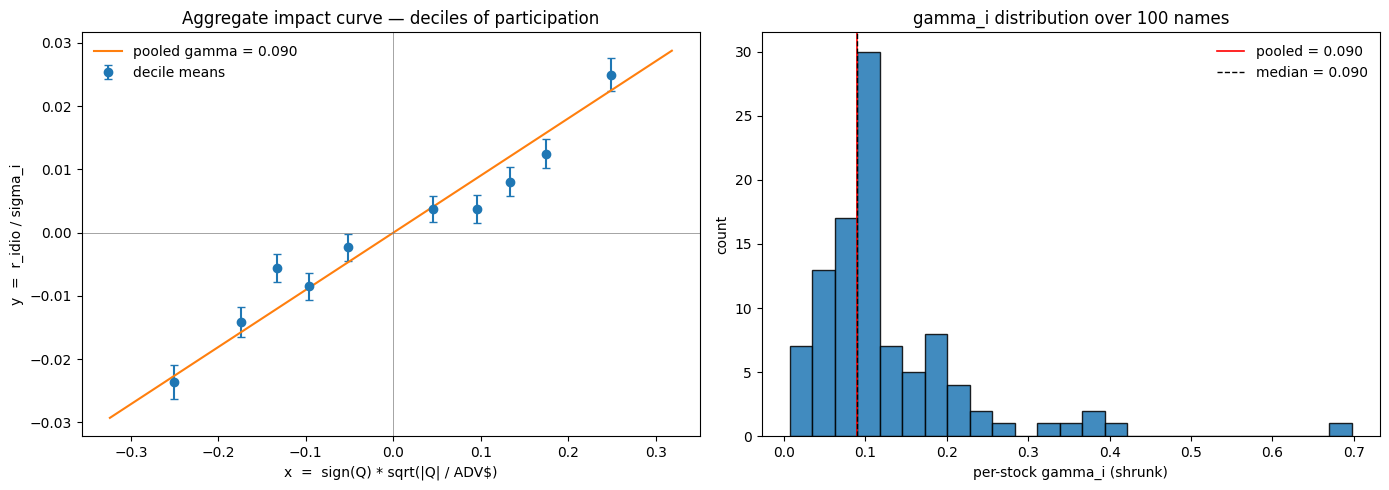

In [13]:
# --- Diagnostic plots -----------------------------------------------------------
# (a) Aggregate impact curve: bin sqrt participation into deciles, plot mean y vs
#     mean x per bin, overlay the pooled-gamma line.  If the model is right the
#     bin means should sit on a straight line through the origin with slope
#     ~gamma_pool.
# (b) Histogram of per-stock (shrunk) gamma_i.
# The plots use the winsorized fit arrays.
n_bins = 10
order = np.argsort(x_w)
x_sorted = x_w[order]
y_sorted = y_w[order]
edges = np.quantile(x_sorted, np.linspace(0, 1, n_bins + 1))
bin_ids = np.clip(np.searchsorted(edges[1:-1], x_sorted), 0, n_bins - 1)

bin_x_mean = np.array([x_sorted[bin_ids == b].mean() for b in range(n_bins)])
bin_y_mean = np.array([y_sorted[bin_ids == b].mean() for b in range(n_bins)])
bin_n      = np.array([(bin_ids == b).sum() for b in range(n_bins)])
bin_y_se   = np.array([y_sorted[bin_ids == b].std(ddof=1) / np.sqrt(max(bin_n[b], 1))
                       for b in range(n_bins)])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.errorbar(bin_x_mean, bin_y_mean, yerr=bin_y_se, fmt="o", capsize=3, label="decile means")
xs = np.linspace(x_w.min(), x_w.max(), 200)
ax.plot(xs, gamma_pool * xs, lw=1.5, label=f"pooled gamma = {gamma_pool:.3f}")
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel("x  =  sign(Q) * sqrt(|Q| / ADV$)")
ax.set_ylabel("y  =  r_idio / sigma_i")
ax.set_title("Aggregate impact curve — deciles of participation")
ax.legend(loc="best", frameon=False)

ax = axes[1]
ax.hist(GAMMA_VEC, bins=25, edgecolor="black", alpha=0.85)
ax.axvline(gamma_pool, color="red", lw=1.2, label=f"pooled = {gamma_pool:.3f}")
ax.axvline(float(np.median(GAMMA_VEC)), color="black", lw=1.0, linestyle="--",
           label=f"median = {float(np.median(GAMMA_VEC)):.3f}")
ax.set_xlabel("per-stock gamma_i (shrunk)")
ax.set_ylabel("count")
ax.set_title(f"gamma_i distribution over {len(GAMMA_VEC)} names")
ax.legend(loc="best", frameon=False)

fig.tight_layout()
plt.show()


## Follow-up (out of scope here)

The optimizer currently consumes a **scalar** `IMPACT_GAMMA` in
`optimizer/optimal_portfolio.ipynb`. Wiring in the per-stock $\gamma$ vector
requires:

1. Loading `impact/impact_gamma_vec.npy` (length-100, ACTIVE_SET-aligned) alongside
   the covariance and forecast artifacts.
2. Changing `Optimizer.set_problem` to accept `gamma` as a vector and multiplying
   inside the objective as `cp.sum(cp.multiply(gamma_vec, impact_coeff *
   cp.power(cp.abs(self.x), 1.5)))`.
3. Mirroring the same change in the *ex-post* PnL accounting so realized and
   expected impact remain consistent.

None of that is touched here — this notebook only produces the vector.

**Sanity check before wiring**: if the notebook prints a pooled $\gamma$ far
outside $O(0.1..1)$, revisit the estimator before shipping — the optimizer's
default scalar was $\gamma = 0.5$, so a fitted value in that ballpark is what to
expect if the calibration is well-posed.
